# Asymmetric cascade for suicide-related text classification

This notebook implements the supervisor revision. The primary question concerns
additional positive text labels detected at a fixed request budget, with the
accompanying false alarms. Word2Vec–XGBoost supplies the first decision. The
Metis Jev API can promote selected comparator negatives to positive.

The archived data support exploratory replay and method development. Fresh
evaluation, a source-verified label definition and provider access remain
pending in the delivered snapshot. A separate collection command uses the
already authorized 10,000-attempt Study 2 ledger.

In [1]:
from pathlib import Path
import json
import sys

from IPython.display import Image, display
import pandas as pd

root = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / 'jev_research').is_dir())
sys.path.insert(0, str(root))
from jev_research.cascade_report import render_revision

official_affiliation = None
analysis, fresh, output = render_revision(root, affiliation=official_affiliation)
display(pd.Series(fresh, name='Fresh Study 2 status'))

actual_new_attempts                                          0
successes                                                    0
failed                                                       0
pending_uncertain                                            0
unused_allowance                                         10000
ledger_exists                                            False
study_id               jev_selective_routing_study2_validation
state                                  fresh sample not frozen
Name: Fresh Study 2 status, dtype: object

## 1. Identify the actual model and reference

`jev-latest` is the exact request alias for the recorded Metis Jev API. The API
record below supplies the prompt, response parser and historical timing. The
provider's backend architecture, immutable version and parameter count are
unavailable. The earlier name “Perplexity Decider” identifies no verified
checkpoint in this project and has been removed from the model comparison.

One input is one exported text record. The known mapping is the dataset's
`suicide` and `non-suicide` classes. Reddit/subreddit origin and the annotation
linkage to IEEE document 9591887 require source verification. A subreddit-derived
label would reflect a proxy for text content. Clinical diagnosis and individual
future outcomes were outside the observed reference.

In [2]:
model = json.loads((output / 'model_and_api.json').read_text())
display(pd.Series(model, name='Metis request identity'))

architecture                                                               None
automatic_retries                                                             0
connect_timeout_seconds                                                      10
endpoint                           https://api.metisai.ir/typesafe/v1/systemone
generation_config             Provider defaults; temperature, seed and token...
historical_attempts                                                        5000
historical_failed_attempts                                                    4
historical_finished_tehran                     2026-10-21T22:59:07.961259+03:30
historical_started_tehran                      2026-10-21T22:37:43.985618+03:30
historical_workers                                                       [2, 4]
immutable_backend_version                                                  None
name                                                              Metis Jev API
parameter_count                         

## 2. Reconstruct original Validation counts and fix the comparator

Historical 0.38 is the rounded 0.383297 cache-development F1 cutoff. The
centralized notebook's earlier 0.44 is from original Validation F1 selection.
The historical replacement and OR audits retain their fixed 0.50 rule.

For the new comparison, use Youden's J on the fully identifiable 0.05 grid of
the original 37,086 Validation records. Below the archived 0.50 threshold, the
bin error count is the positive class count. At and above it, the bin error
count is the negative class count. The grid produces an exact confusion table
without using old or new evaluation labels. Apply the chosen comparator to
every revised policy.

In [3]:
grid = analysis['threshold_grid']
display(grid[['threshold', 'recall', 'specificity', 'precision', 'f1', 'f2', 'youden_j', 'selected']].round(4))
display(grid.loc[grid.selected, ['threshold', 'tn', 'fp', 'fn', 'tp', 'n']])

,threshold,recall,specificity,precision,f1,f2,youden_j,selected
0,0.00,1.0000,0.0000,0.5005,0.6671,0.8336,0.0000,False
1,0.05,0.9940,0.6085,0.7178,0.8336,0.9230,0.6025,False
2,0.10,0.9872,0.7294,0.7852,0.8747,0.9389,0.7166,False
3,0.15,0.9810,0.7867,0.8217,0.8943,0.9444,0.7677,False
4,0.20,0.9739,0.8239,0.8471,0.9061,0.9456,0.7978,False
5,0.25,0.9657,0.8495,0.8654,0.9128,0.9438,0.8152,False
6,0.30,0.9580,0.8697,0.8805,0.9176,0.9414,0.8277,False
7,0.35,0.9510,0.8859,0.8931,0.9211,0.9388,0.8369,False
8,0.40,0.9440,0.9000,0.9044,0.9238,0.9358,0.8440,False
9,0.45,0.9362,0.9109,0.9133,0.9246,0.9315,0.8471,True


,threshold,tn,fp,fn,tp,n
9,0.45,16875,1650,1185,17376,37086


## 3. Select a supported uncertainty interval and calibrate the score

The historical bin peak of [0.45, 0.50) was measured under a comparator cutoff
of 0.50. At the revised comparator threshold, those records are already
positive. Candidate referral intervals end at the revised XGBoost cutoff.
Intervals starting at 0.15 or 0.20 need outcomes below the 0.25 archive boundary.

Fit sigmoid calibration in five folds on covered comparator negatives in the
2,000-record cached development split. Use out-of-fold scores to choose the
lower edge and calibrated cutoff by positive F2 gain per attempted referral,
with at least 100 development referrals. Refit the final sigmoid on the same
development pool and hold its coefficients fixed. The calibrated target is the
supplied textual label in that score range. The old raw 0.03 and 0.08 operating
points are historical and have no interpretation as clinical probabilities.

architecture                                                  asymmetric_or
xgb_threshold                                                          0.45
routing_interval                                                [0.4, 0.45]
calibrated_jev_cutoff                                                   0.4
calibration_slope                                                  0.480215
calibration_intercept                                              0.335402
calibration_fit_rows                                                    707
calibration_folds                                                         5
calibration_logit_clip                                             0.000001
selection_metric          positive development F2 gain per prospective r...
fallback                             retain tuned Word2Vec–XGBoost decision
model                                                            jev-latest
endpoint                       https://api.metisai.ir/typesafe/v1/systemone
question    

,lower,upper_exclusive,status,requests,calibrated_cutoff,positive_recoveries,added_false_alarms,delta_f2,delta_f2_per_100_requests,selected
0,0.15,0.45,JEV coverage below 0.25 is absent,NaN,NaN,NaN,NaN,NaN,NaN,False
1,0.20,0.45,JEV coverage below 0.25 is absent,NaN,NaN,NaN,NaN,NaN,NaN,False
2,0.25,0.45,scored on development,707.0,0.4,203.0,66.0,0.13617,0.01926,False
3,0.25,0.45,scored on development,707.0,0.5,182.0,46.0,0.12456,0.01762,False
4,0.25,0.45,scored on development,707.0,0.6,156.0,25.0,0.10943,0.01548,False
5,0.25,0.45,scored on development,707.0,0.7,137.0,20.0,0.09674,0.01368,False
6,0.25,0.45,scored on development,707.0,0.8,108.0,14.0,0.07694,0.01088,False
7,0.30,0.45,scored on development,508.0,0.4,154.0,55.0,0.10373,0.02042,False
8,0.30,0.45,scored on development,508.0,0.5,134.0,38.0,0.09206,0.01812,False
9,0.30,0.45,scored on development,508.0,0.6,114.0,21.0,0.08025,0.01580,False


,score,n,brier,log_loss,ap
0,Raw Metis rating,1090,0.1490,0.5905,0.826
1,Sigmoid calibration,1090,0.1277,0.3987,0.826


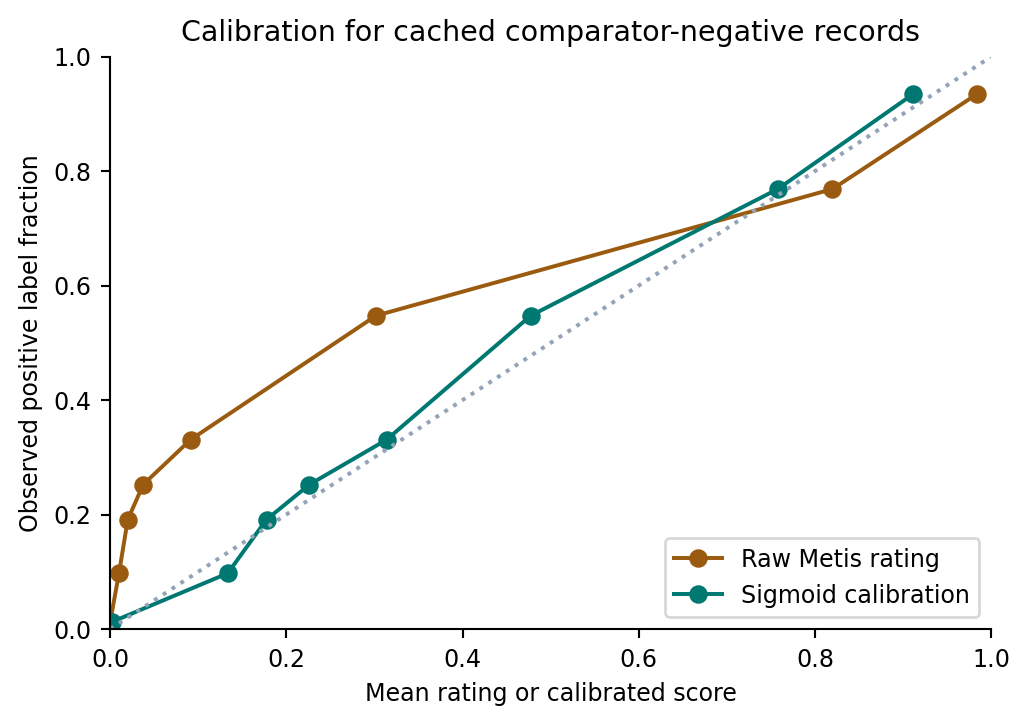

In [4]:
display(pd.Series(analysis['policy'], name='Revised decision rule'))
display(analysis['routing_sweep'].round(5))
display(analysis['calibration_audit'].round(4))
display(Image(filename=str(output / 'figures/calibration.png')))

## 4. Replay paired decisions and compare equal-budget referral

All three policies below use the same XGBoost cutoff and cached denominator.
A successful JEV decision can promote a comparator negative, and an
unavailable score retains the comparator decision. Random referral applies
the same downstream decision to a uniform sample of comparator negatives.
Here the comparison is restricted to observable cached negatives. The
population design uses exterior controls from the entire residual frame.

The 3,000 records were separate from the current development fit. All 5,000
historical records had already been inspected in the earlier studies. Paired
intervals and exact McNemar tests describe this exploratory replay; author
metadata necessary for cluster inference are absent. Expected random totals
are evaluated with paired bootstrap contrasts.

,policy,precision,recall,f1,f2,tp,fp,fn,tn,requests
0,Word2Vec–XGBoost,0.638,0.753,0.690,0.727,1217.000,692.00,399.000,692.00,0.0
1,Asymmetric cascade,0.645,0.804,0.716,0.766,1300.000,717.00,316.000,667.00,239.0
2,Equal-budget random referral,0.642,0.793,0.710,0.757,1281.405,713.03,334.595,670.97,239.0


,difference,ci95
accuracy,0.019333,"[0.012666666666666604, 0.02633333333333332]"
recall,0.051361,"[0.04076527577608497, 0.06242517006802728]"
specificity,-0.018064,"[-0.025623232046719555, -0.011227676760225711]"
precision,0.007015,"[0.002362358442584578, 0.011688436508001264]"
f2,0.039678,"[0.03085322292069041, 0.049014356272255796]"


,metric,estimate,ci_low,ci_high,scope
0,recall_difference,0.01151,0.00251,0.02137,"3,000 reused cache rows; random pool restricte..."
1,additional_false_alarms_per_1000,1.32325,-1.45768,4.24695,"3,000 reused cache rows; random pool restricte..."


,comparison,endpoint,n,corrected,new_errors,mcnemar_exact_p
0,Asymmetric cascade vs Word2Vec–XGBoost,all: correct classifications,3000,83,25,1.882934e-08
1,Asymmetric cascade vs Word2Vec–XGBoost,positive: sensitivity,1616,83,0,2.067952e-25
2,Asymmetric cascade vs Word2Vec–XGBoost,negative: specificity,1384,0,25,5.960464e-08
3,Historical score replacement at 0.50,all: correct classifications,3000,811,367,5.105776e-39
4,Historical score replacement at 0.50,positive: sensitivity,1616,310,312,9.680206e-01
5,Historical score replacement at 0.50,negative: specificity,1384,501,55,4.510604e-91


n                              5000.000000
referrals                      2184.000000
recovered_positives             538.000000
added_false_alarms               96.000000
new_missed_positives              0.000000
selected_misses                 322.000000
selected_false_alarms          1049.000000
full_frame_n                  46342.000000
full_frame_baseline_recall        0.920895
full_frame_replayed_recall        0.944088
Name: Historical OR at 0.50, dtype: float64

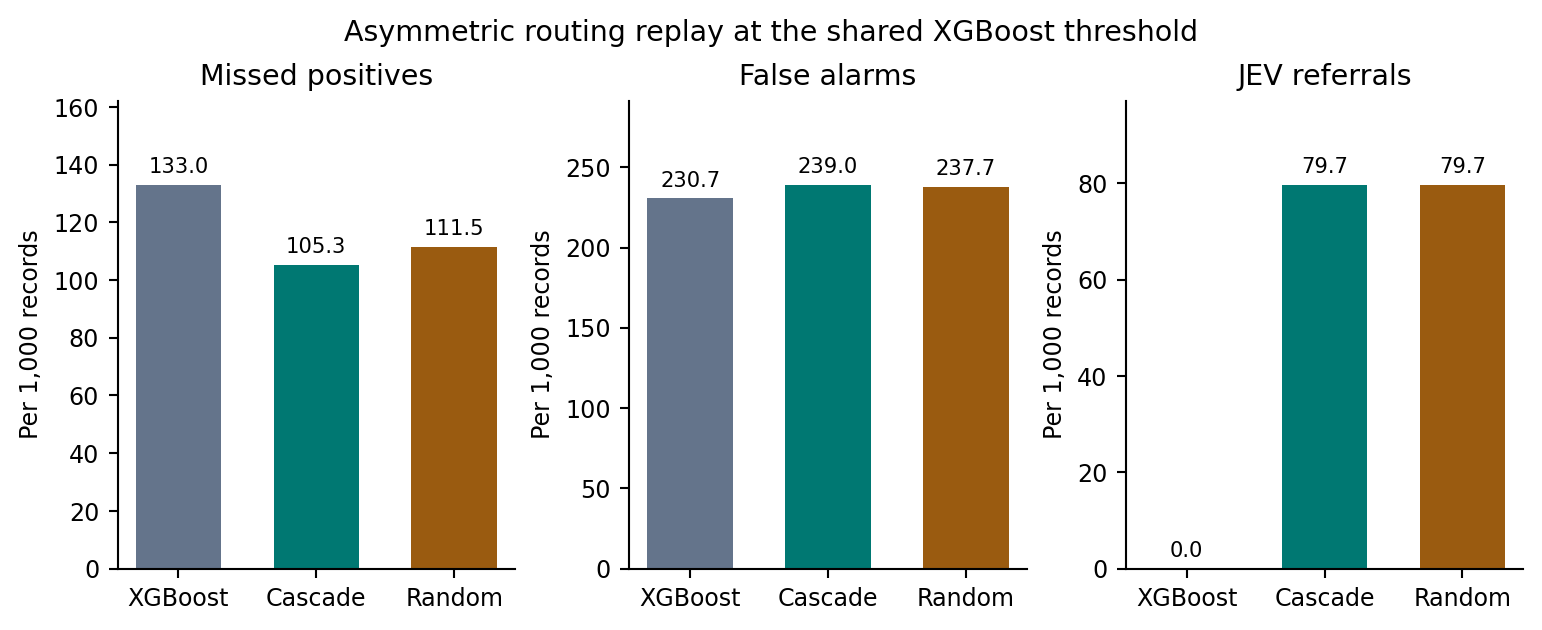

In [5]:
columns = ['policy', 'precision', 'recall', 'f1', 'f2', 'tp', 'fp', 'fn', 'tn', 'requests']
display(analysis['archive_replay'][columns].round(3))
display(pd.DataFrame(analysis['paired_intervals']).T)
display(analysis['random_contrast'].round(5))
display(analysis['mcnemar'])
display(pd.Series(analysis['historical_or'], name='Historical OR at 0.50'))
display(Image(filename=str(output / 'figures/cached_routing_outcomes.png')))

## 5. Audit the continuous ROC and precision–recall curves

The paired continuous-score comparison uses XGBoost alone and the historical
replacement score with fallback on failed calls. DeLong variance accounts for
paired scores and tied ratings under a record-independence assumption. Average
precision and trapezoidal PR-AUC use separate numerical definitions. The curves
apply to the restricted historical score cohort. The revised cascade produces
binary decisions at a fixed operating point.

,model,n,roc_auc,average_precision,pr_auc_trapezoidal
0,Word2Vec–XGBoost,3000,0.6822,0.7050,0.7047
1,Historical Metis score replacement,3000,0.8911,0.8901,0.8973


n                                                                  3000
positives                                                          1616
negatives                                                          1384
xgb_roc_auc                                                    0.682157
comparison_roc_auc                                             0.891051
delta_auc                                                      0.208894
standard_error                                                  0.01027
ci_low                                                         0.188766
ci_high                                                        0.229023
p_value                                                             0.0
scope                 exploratory; row independence assumed, author ...
Name: Paired ROC-AUC audit, dtype: object

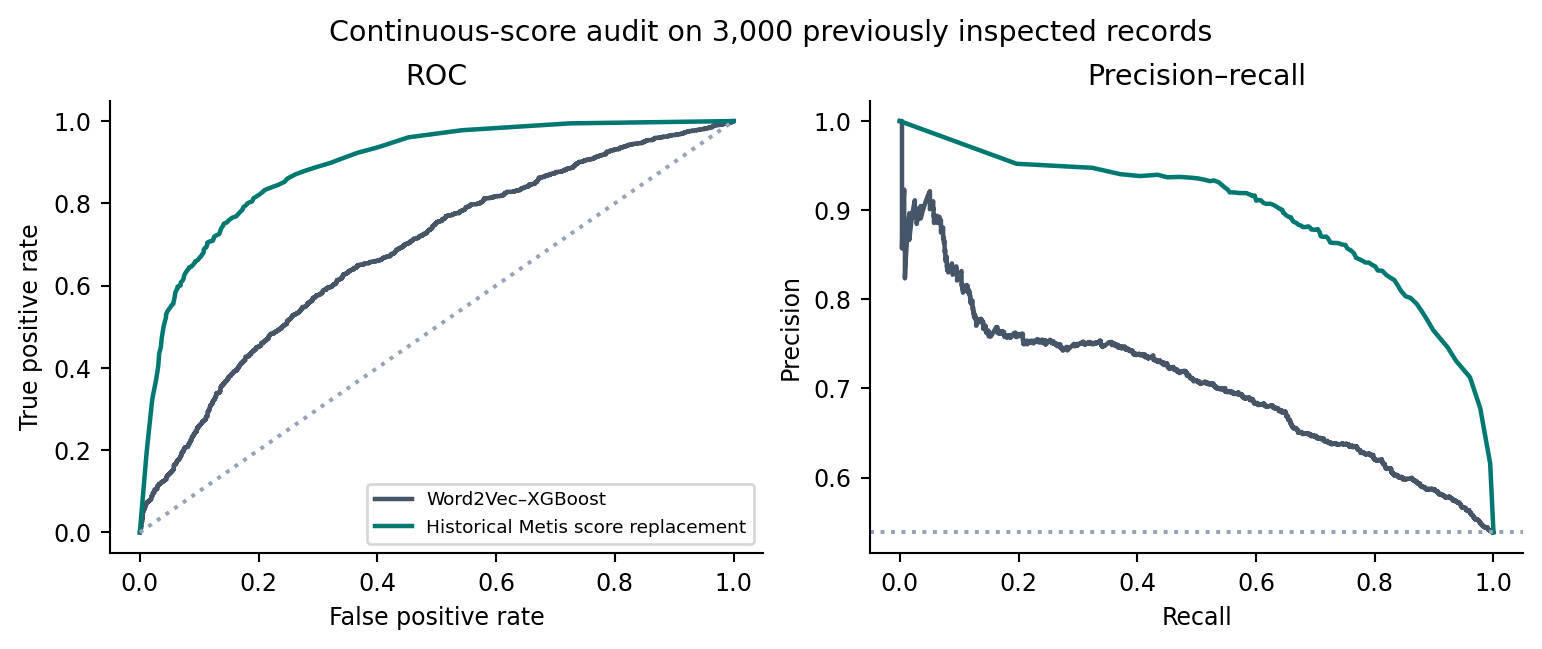

In [6]:
display(analysis['ranking'].round(4))
display(pd.Series(analysis['delong'], name='Paired ROC-AUC audit'))
display(Image(filename=str(output / 'figures/continuous_scores_roc_pr.png')))

## 6. Prepare the independent evaluation and record resources

The 1,067 remaining texts in the original interval require provenance and prior
exclusion checks. The earlier error study accounts for five of them. The old
test's aggregate exposure persists even after disjoint record selection. The
revised sampler takes a census of the new uncertainty band and comparator
positives, plus a probability sample of other comparator negatives. Only
sampled negatives require provider responses. The sample manifest and reference
digest are sealed before collection; labels are read for metrics after the
planned attempts are accounted for.

An actual later source or author/time split would strengthen independence. In
the current environment, the source and full private corpus were unavailable.
The TF-IDF and Word2Vec–XGBoost resource commands will use the restored original
training and Validation splits. The historical prepared-batch timing is already
available. Provider token counts and verified USD costs require usage and
pricing records. All-referral is a hypothetical 1,000 requests per 1,000 texts.

In [7]:
display(pd.Series(json.loads((output / 'residual_frame_accounting.json').read_text()), name='Residual frame'))
display(pd.Series(json.loads((output / 'resource_accounting.json').read_text()), name='Resource evidence'))
if fresh['state'] == 'replayed':
    display(pd.read_json(output / 'fresh_population.json', precise_float=True))
    display(pd.read_json(output / 'fresh_paired.json', precise_float=True))
    display(pd.read_json(output / 'fresh_strata.json', precise_float=True))
else:
    display(pd.read_json(output / 'fresh_results_pending.json', precise_float=True))
print('Manuscript and reproducibility tables:', output.relative_to(root))

additional_prior_test_inside_old_interval_n           5.0
additional_prior_test_n                              19.0
old_interval_n                                     6067.0
original_test_n                                   46342.0
potential_old_interval_n                           1062.0
potential_test_n                                  41323.0
revised_route_n                                       NaN
unqueried_in_old_interval_before_other_history     1067.0
Name: Residual frame, dtype: float64

archive_test_n                                                                                       46342
archived_fit_seconds                                                                            279.195604
archived_prepared_prediction_seconds_per_1000                                                     0.002895
archived_prepared_timing_scope                           Word2Vec embedding and XGBoost score predictio...
archived_test_prediction_seconds                                                                  0.134163
archived_xgb_cpu_threads                                                                                 1
historical_jev_active_batch_seconds_per_1000_attempts                                           200.335247
historical_jev_active_phase_wall_seconds                                                       1001.676233
historical_jev_calendar_wall_seconds                                                           1283.975641
hypothetical_all_referral_requests_pe

,stratum,n,status
0,uncertain_negative,NaN,fresh sample not frozen
1,other_negative,NaN,fresh sample not frozen
2,comparator_positive,NaN,fresh sample not frozen


Manuscript and reproducibility tables: research/results/jev_asymmetric_cascade_revision
